# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:
!pip install kagglehub --quiet

import kagglehub
import os
import glob

# Baixar o dataset de clima de Curitiba
path = kagglehub.dataset_download("paulogladson/clima-curitiba")


# Encontrar o arquivo CSV
arquivos_csv = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

print("Arquivos encontrados:")
print(arquivos_csv)

df = pd.read_csv(
    arquivos_csv[0],
    sep=';',
    decimal=',',
    low_memory=False
)

df.head()

Using Colab cache for faster access to the 'clima-curitiba' dataset.
Arquivos encontrados:
['/kaggle/input/clima-curitiba/CURITIBA.csv']


,Unnamed: 0,Data,Hora_UTC,PRECIPITAÇÃO_TOTAL__HORÁRIO_(mm),PRESSAO_ATMOSFERICA_AO_NIVEL_DA_ESTACAO__HORARIA_(mB),PRESSÃO_ATMOSFERICA_MAX.NA_HORA_ANT._(AUT)_(mB),PRESSÃO_ATMOSFERICA_MIN._NA_HORA_ANT._(AUT)_(mB),RADIACAO_GLOBAL_(Kj/m²),TEMPERATURA_DO_AR_-_BULBO_SECO__HORARIA_(°C),TEMPERATURA_DO_PONTO_DE_ORVALHO_(°C),...,VENTO__RAJADA_MAXIMA_(m/s),VENTO__VELOCIDADE_HORARIA_(m/s),municipio,RADIACAO_GLOBAL_(KJ/m²),Diaano,TEMPERATURA_MEDIA,UMIDADE_MEDIA,date_month,date_year,date_day
0,0,2003-01-28,00:00,0,915.9,915.9,915.3,NaN,17.9,17.9,...,4.4,1.7,CURITIBA,.3,28,17.799999999999997,91.0,1,2003,28
1,1,2003-01-28,01:00,0,915.8,916,915.8,NaN,17.7,16.5,...,5.3,1.9,CURITIBA,.2,28,17.799999999999997,89.0,1,2003,28
2,2,2003-01-28,02:00,0,915.4,915.8,915.4,NaN,17.3,17,...,4.9,2.1,CURITIBA,.3,28,17.45,91.0,1,2003,28
3,3,2003-01-28,03:00,0,915.7,915.7,915.4,NaN,17.3,17.2,...,4.3,1.3,CURITIBA,.4,28,17.200000000000003,93.5,1,2003,28
4,4,2003-01-28,04:00,0,914.9,915.7,914.9,NaN,17.4,17.4,...,3.3,1.5,CURITIBA,NaN,28,17.299999999999997,95.0,1,2003,28


## 1. Princípio Estrutural


### Dimensão e Tipos de Dados

In [3]:
df.shape

(206808, 28)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206808 entries, 0 to 206807
Data columns (total 28 columns):
 #   Column                                                 Non-Null Count   Dtype 
---  ------                                                 --------------   ----- 
 0   Unnamed: 0                                             206808 non-null  int64 
 1   Data                                                   206808 non-null  object
 2   Hora_UTC                                               206808 non-null  object
 3   PRECIPITAÇÃO_TOTAL__HORÁRIO_(mm)                       206808 non-null  object
 4   PRESSAO_ATMOSFERICA_AO_NIVEL_DA_ESTACAO__HORARIA_(mB)  206808 non-null  object
 5   PRESSÃO_ATMOSFERICA_MAX.NA_HORA_ANT._(AUT)_(mB)        206808 non-null  object
 6   PRESSÃO_ATMOSFERICA_MIN._NA_HORA_ANT._(AUT)_(mB)       206808 non-null  object
 7   RADIACAO_GLOBAL_(Kj/m²)                                51990 non-null   object
 8   TEMPERATURA_DO_AR_-_BULBO_SECO__HORARIA_(°C)

In [5]:
df.describe()

,Unnamed: 0,UMIDADE_RELATIVA_DO_AR__HORARIA_(%),VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),Diaano,date_month,date_year,date_day
count,206808.000000,206808.000000,206808.000000,206808.000000,206808.000000,206808.000000,206808.000000
mean,4328.564408,76.218043,140.194727,181.936753,6.483811,2014.372868,15.734710
std,2515.875878,17.324627,101.048474,104.843855,3.429227,6.814821,8.802468
min,0.000000,12.000000,1.000000,1.000000,1.000000,2003.000000,1.000000
25%,2154.000000,65.000000,68.000000,91.000000,4.000000,2008.000000,8.000000
50%,4308.000000,81.000000,96.000000,181.000000,6.000000,2014.000000,16.000000
75%,6490.000000,90.000000,238.000000,272.000000,9.000000,2020.000000,23.000000
max,8783.000000,100.000000,360.000000,366.000000,12.000000,2026.000000,31.000000


### Duplicadas

In [6]:
df.duplicated().sum()

np.int64(0)

### Verificando a existência de um atributo-alvo
> Adicionar aspas



O dataset de clima de Curitiba não possui um atributo-alvo específico equivalente ao num do dataset Heart Disease. Portanto, não é necessário realizar a transformação de uma variável alvo nesta etapa. As variáveis meteorológicas serão analisadas diretamente ao longo da EDA.

## 2. Dados Faltantes

In [7]:
df.isna().sum()

,0
Unnamed: 0,0
Data,0
Hora_UTC,0
PRECIPITAÇÃO_TOTAL__HORÁRIO_(mm),0
PRESSAO_ATMOSFERICA_AO_NIVEL_DA_ESTACAO__HORARIA_(mB),0
PRESSÃO_ATMOSFERICA_MAX.NA_HORA_ANT._(AUT)_(mB),0
PRESSÃO_ATMOSFERICA_MIN._NA_HORA_ANT._(AUT)_(mB),0
RADIACAO_GLOBAL_(Kj/m²),154818
TEMPERATURA_DO_AR_-_BULBO_SECO__HORARIA_(°C),0
TEMPERATURA_DO_PONTO_DE_ORVALHO_(°C),0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim. O dataset possui dados ausentes em duas features relacionadas à radiação global. A coluna RADIACAO_GLOBAL_(Kj/m²) possui 154.818 valores ausentes e a coluna RADIACAO_GLOBAL_(KJ/m²) possui 84.154 valores ausentes. As demais colunas não apresentam valores ausentes.

#### Identificando o mecanismo de dados ausentes

No dataset atual temos duas features relacionadas à radiação global com dados ausentes:

RADIACAO_GLOBAL_(Kj/m²) — 154.818 valores ausentes;
RADIACAO_GLOBAL_(KJ/m²) — 84.154 valores ausentes.

Como os dados foram coletados:
O conjunto contém dados meteorológicos históricos de Curitiba extraídos do portal do INMET.

Qual a natureza da fonte de dados:
Os dados correspondem a observações meteorológicas registradas ao longo do tempo. Apenas com a análise dos dados não é possível determinar com certeza a causa das ausências nas medições de radiação global.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [8]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()

print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['RADIACAO_GLOBAL_(Kj/m²)', 'RADIACAO_GLOBAL_(KJ/m²)']
RADIACAO_GLOBAL_(Kj/m²)    154818
RADIACAO_GLOBAL_(KJ/m²)     84154
dtype: int64


Como há uma quantidade elevada de valores ausentes nas duas colunas de radiação global, é importante verificar se essas ausências ocorrem simultaneamente nas mesmas observações.

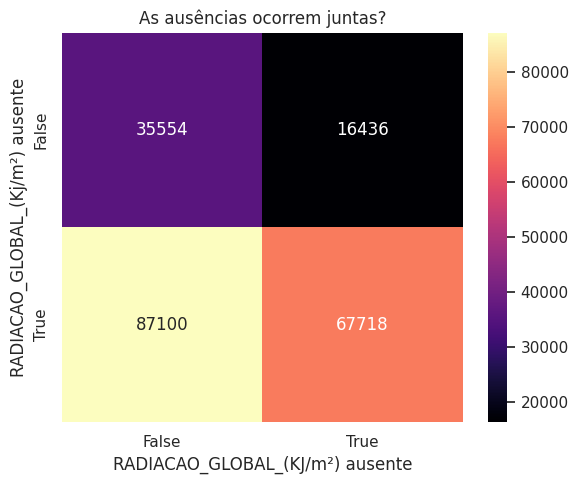

In [9]:
tabela_contingencia = pd.crosstab(
    df[cols_com_ausentes[0]].isna(),
    df[cols_com_ausentes[1]].isna(),
    rownames=[f"{cols_com_ausentes[0]} ausente"],
    colnames=[f"{cols_com_ausentes[1]} ausente"]
)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

Existem 67.718 linhas em que as duas colunas de radiação global estão ausentes ao mesmo tempo. Isso mostra que há uma ocorrência conjunta relevante das ausências. Porém, apenas com esses dados não é possível determinar se o mecanismo é MCAR, MAR ou MNAR, sendo necessário conhecimento adicional sobre o processo de coleta dos dados.

In [10]:
percentual_ausentes = df.isna().mean() * 100
percentual_ausentes[percentual_ausentes > 0]

,0
RADIACAO_GLOBAL_(Kj/m²),74.860740
RADIACAO_GLOBAL_(KJ/m²),40.691849


Como critério de tratamento, serão removidas colunas com pelo menos 50% de valores ausentes. A coluna RADIACAO_GLOBAL_(Kj/m²) apresenta aproximadamente 74,86% de dados faltantes e, portanto, será removida. A coluna RADIACAO_GLOBAL_(KJ/m²) apresenta aproximadamente 40,69% de valores ausentes e será mantida.

In [11]:
df.shape

(206808, 28)

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [12]:
VARS_QUANT = [
    "UMIDADE_RELATIVA_DO_AR__HORARIA_(%)",
    "VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr))",
    "Diaano",
    "date_month",
    "date_year",
    "date_day"
]

VARS_QUAL = [
    "Data",
    "Hora_UTC",
    "municipio"
]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
UMIDADE_RELATIVA_DO_AR__HORARIA_(%),76.22,81.00,17.32,12.00,100.00,-0.88,0.03
VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),140.19,96.00,101.05,1.00,360.00,0.77,-0.85
Diaano,181.94,181.00,104.84,1.00,366.00,0.02,-1.19
date_month,6.48,6.00,3.43,1.00,12.00,0.01,-1.19
date_year,2014.37,2014.00,6.81,2003.00,2026.00,0.00,-1.20
date_day,15.73,16.00,8.80,1.00,31.00,0.01,-1.19


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Nenhuma das variáveis quantitativas analisadas apresentou assimetria acima de 1 em módulo ou curtose acima de 2 em módulo. A umidade relativa do ar apresentou assimetria negativa moderada (-0,89), enquanto a direção do vento apresentou assimetria positiva moderada (0,75), mas ambas permanecem abaixo do critério adotado. Portanto, não foram identificadas distribuições fortemente assimétricas ou com caudas pesadas nesta análise.

### Distribuições de dados

Nesta etapa, serão visualizadas as distribuições das variáveis quantitativas do dataset de clima de Curitiba.

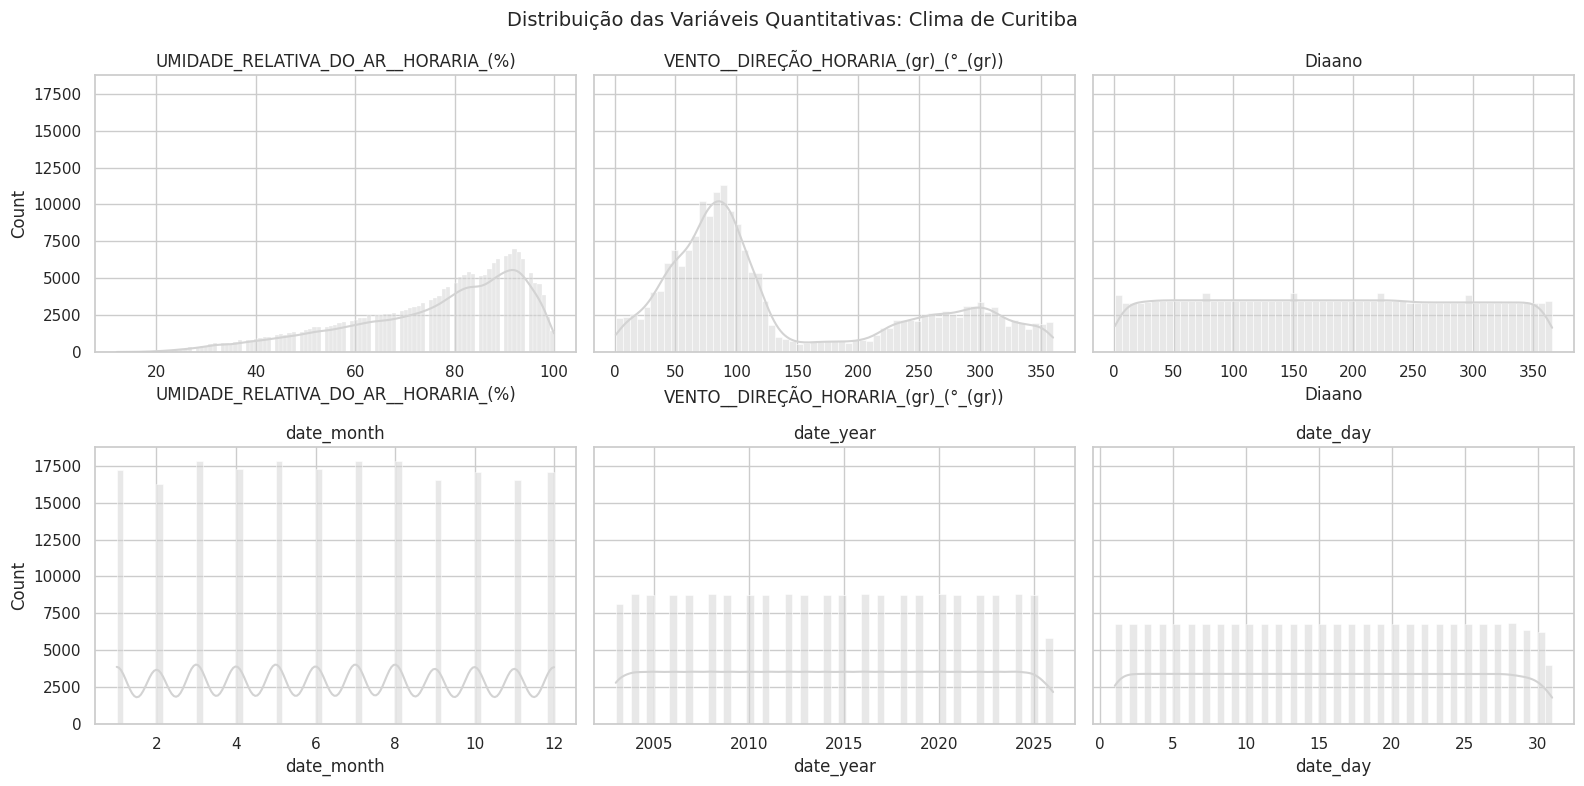

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Clima de Curitiba", fontsize=14)
plt.tight_layout()
plt.show()

Esta comparação por classes não se aplica ao dataset de clima de Curitiba, pois o conjunto não possui uma variável-alvo categórica equivalente às classes “Normal” e “Cardíaco” do dataset Heart Disease.

#### Testes de Aderência

Será que a umidade relativa do ar segue uma distribuição normal?
O Shapiro-Wilk será utilizado como teste de aderência à normalidade, junto com o QQ-Plot como visualização de apoio. Vamos testar a variável de umidade relativa do ar.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 206808.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — Umidade relativa do ar: estatística=0.9219, p-valor=1.905e-120
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


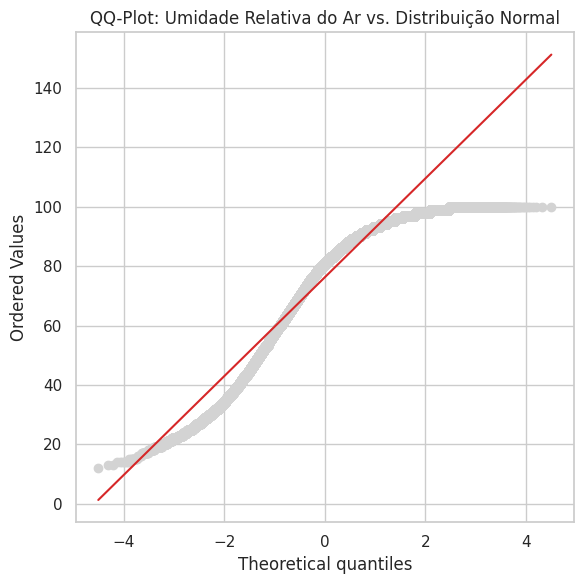

In [14]:
stat_sw, p_valor_sw = stats.shapiro(
    df["UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"].dropna()
)

print(
    f"Shapiro-Wilk — Umidade relativa do ar: "
    f"estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}"
)

print(
    "Rejeita H0 (normalidade)?",
    "Sim" if p_valor_sw < 0.05 else "Não",
    "(alpha = 0.05)"
)

"""### QQ-Plot — Umidade relativa do ar"""

fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(
    df["UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"].dropna(),
    dist="norm",
    plot=ax
)

ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)

ax.set_title("QQ-Plot: Umidade Relativa do Ar vs. Distribuição Normal")

plt.tight_layout()
plt.show()

**Como ler:** se os pontos seguissem a reta vermelha de perto, a umidade relativa do ar apresentaria comportamento próximo de uma distribuição normal. No QQ-Plot, os pontos se afastam da reta de referência, principalmente nas extremidades, indicando desvios em relação à normalidade. Esse resultado é coerente com o teste de Shapiro-Wilk.

**Nota:** como o dataset possui aproximadamente 206 mil observações, o teste de Shapiro-Wilk se torna muito sensível e o próprio SciPy alerta que o p-valor pode perder precisão para amostras muito grandes. Por isso, o resultado deve ser interpretado em conjunto com o QQ-Plot e as estatísticas descritivas.

O teste apresentou estatística de aproximadamente **0,9219** e p-valor muito menor que 0,05. Portanto, rejeitamos H0 e concluímos que há evidência estatística contra a normalidade da distribuição da umidade relativa do ar. O afastamento dos pontos da reta no QQ-Plot reforça essa conclusão.

In [15]:
resultados_shapiro = []

for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05
    })

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
UMIDADE_RELATIVA_DO_AR__HORARIA_(%),0.9219,0.0,True
VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),0.8613,0.0,True
Diaano,0.9562,0.0,True
date_month,0.9430,0.0,True
date_year,0.9525,0.0,True
date_day,0.9540,0.0,True


ECDF — outra forma de ver a distribuição

Diferente do histograma, a ECDF não depende da escolha do número de bins. Para cada valor no eixo X, a curva mostra a proporção acumulada de observações menores ou iguais àquele valor.

Vamos utilizar a variável de umidade relativa do ar para visualizar sua distribuição acumulada.

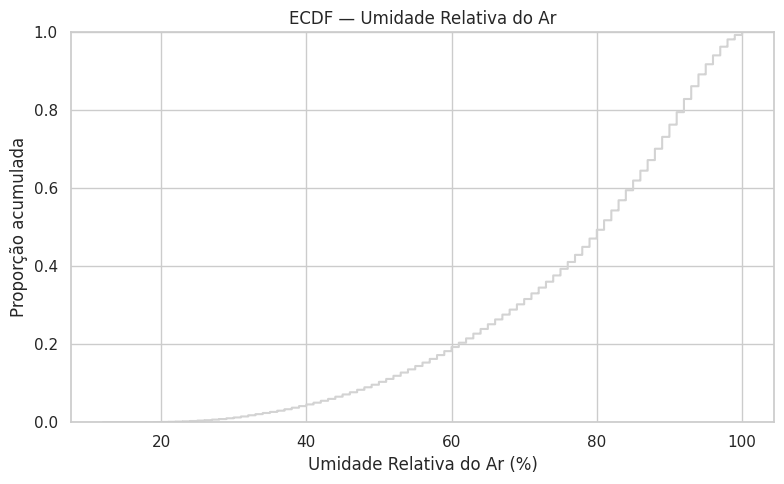

In [16]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(
    data=df,
    x="UMIDADE_RELATIVA_DO_AR__HORARIA_(%)",
    color=COR_NEUTRA
)

plt.title("ECDF — Umidade Relativa do Ar")
plt.xlabel("Umidade Relativa do Ar (%)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

Como ler: em qualquer ponto do eixo X, a altura da curva representa a proporção de observações cuja umidade relativa do ar é menor ou igual àquele valor. Por exemplo, quanto maior a altura da curva em determinado nível de umidade, maior a parcela das observações acumuladas até aquele ponto. A ECDF permite visualizar a distribuição sem depender da escolha de intervalos, como ocorre no histograma.

### Métricas de Tendência Central
---



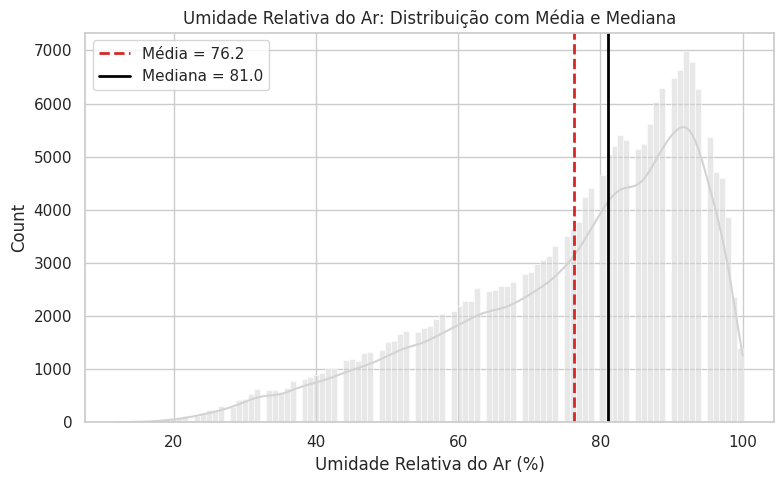

In [17]:
media_umidade = df["UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"].mean()
mediana_umidade = df["UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"].median()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="UMIDADE_RELATIVA_DO_AR__HORARIA_(%)",
    kde=True,
    color=COR_NEUTRA
)

plt.axvline(
    media_umidade,
    color=COR_ALERTA,
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_umidade:.1f}"
)

plt.axvline(
    mediana_umidade,
    color="black",
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {mediana_umidade:.1f}"
)

plt.title("Umidade Relativa do Ar: Distribuição com Média e Mediana")
plt.xlabel("Umidade Relativa do Ar (%)")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

,var,std,IQR
UMIDADE_RELATIVA_DO_AR__HORARIA_(%),300.14,17.32,25.0
VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),10210.79,101.05,170.0
Diaano,10992.23,104.84,181.0
date_month,11.76,3.43,5.0
date_year,46.44,6.81,12.0
date_day,77.48,8.80,15.0


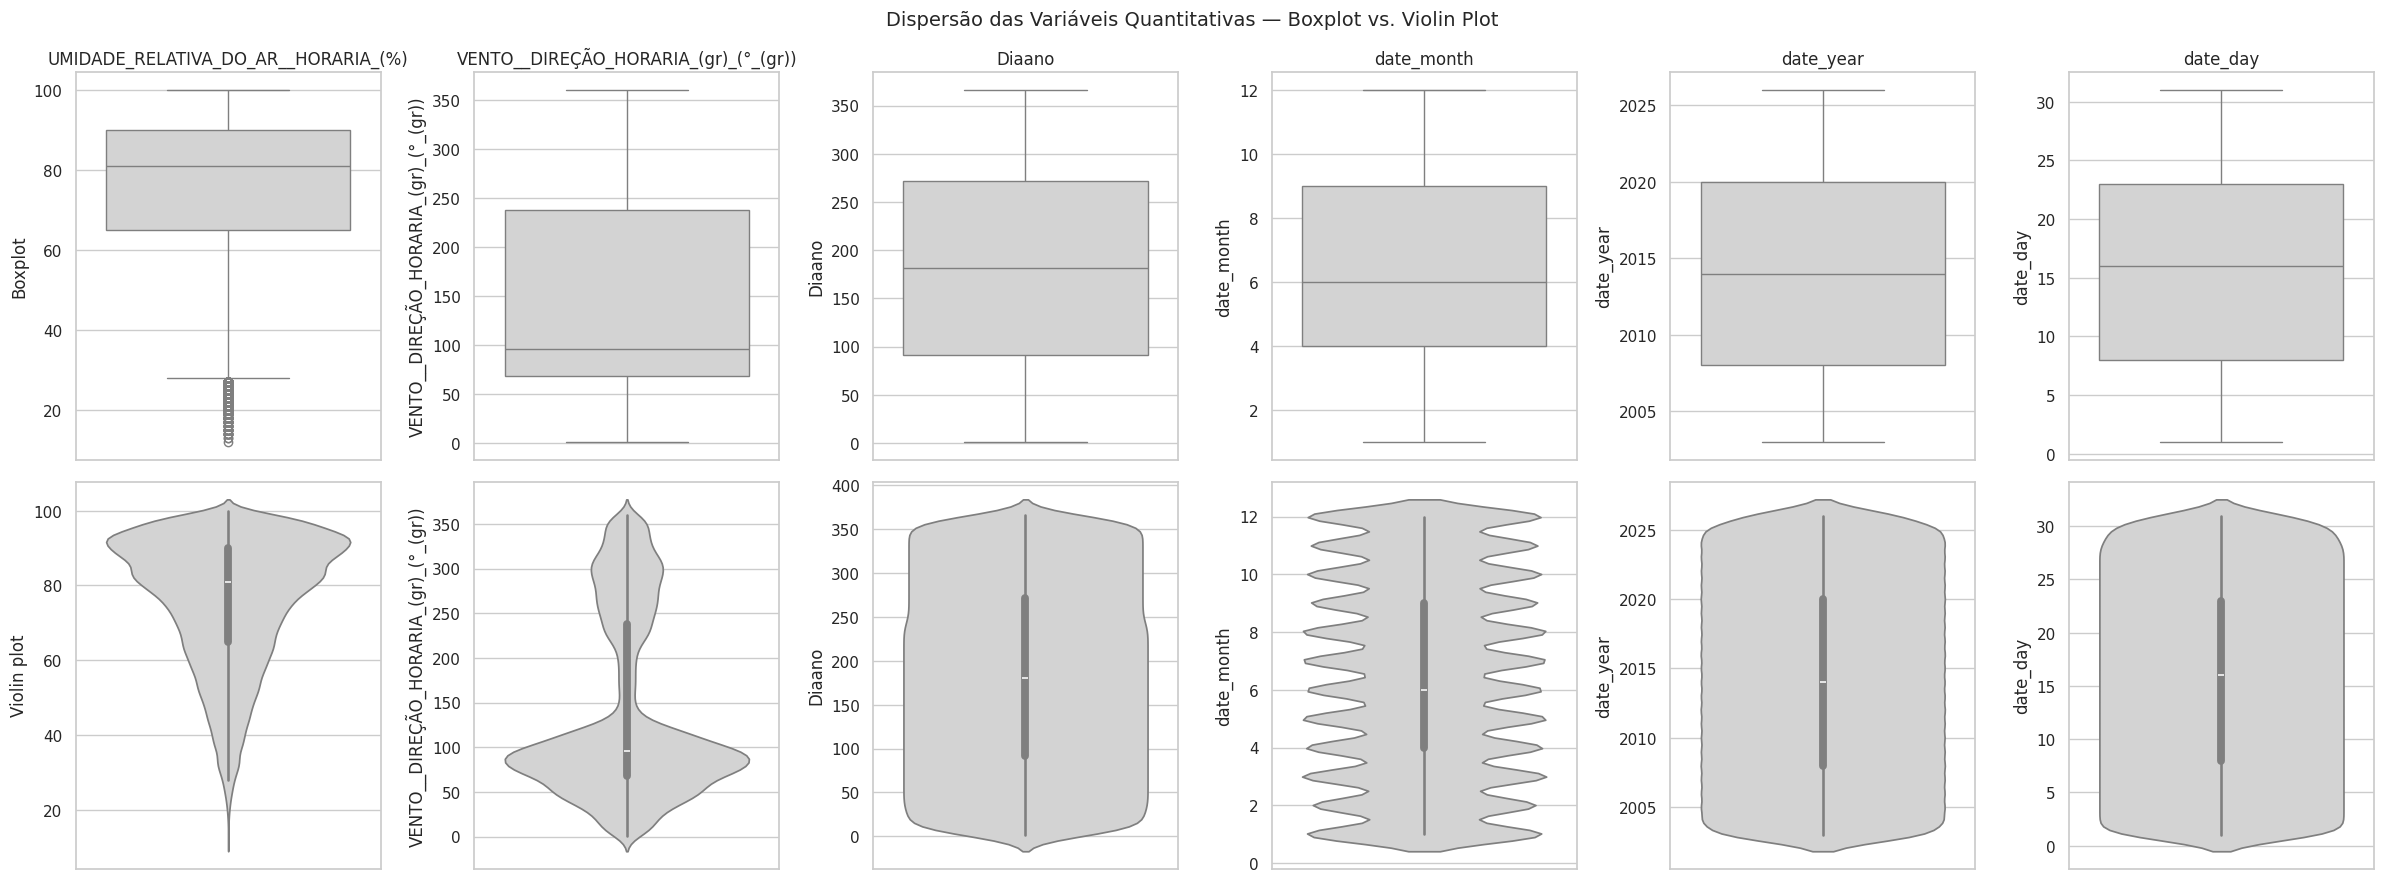

In [18]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)

display(dispersao.round(2))

### Boxplot e violin plot

fig, axes = plt.subplots(
    2,
    len(VARS_QUANT),
    figsize=(4 * len(VARS_QUANT), 9)
)

for i, col in enumerate(VARS_QUANT):

    sns.boxplot(
        data=df,
        y=col,
        color=COR_NEUTRA,
        ax=axes[0, i]
    )

    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(
        data=df,
        y=col,
        color=COR_NEUTRA,
        ax=axes[1, i]
    )

    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")

fig.suptitle(
    "Dispersão das Variáveis Quantitativas — Boxplot vs. Violin Plot",
    fontsize=14
)

plt.tight_layout()
plt.show()

Pra discutir: quais variáveis apresentam maior dispersão? Os boxplots indicam possíveis valores extremos? O formato dos violin plots confirma o comportamento observado nas distribuições anteriores?

Resposta: As maiores dispersões, considerando o IQR e o desvio-padrão, aparecem em Diaano e na direção horária do vento. No entanto, Diaano representa uma variável temporal, então sua dispersão deve ser interpretada com cautela. Nos boxplots, a umidade relativa do ar apresenta possíveis valores extremos na parte inferior da distribuição. O violin plot também confirma que a umidade está mais concentrada em valores elevados, enquanto a direção do vento apresenta mais de uma região de concentração, comportamento que já havia aparecido nos histogramas.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já analisamos o retrato estatístico dos dados, temos informações para decidir como tratar os dados ausentes e os possíveis outliers das variáveis quantitativas. Após o tratamento, as estatísticas descritivas poderão ser analisadas novamente para verificar o efeito das decisões tomadas.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [19]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumo_outliers = {}

for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()

    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
UMIDADE_RELATIVA_DO_AR__HORARIA_(%),27.5,127.5,1406.0
VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),-187.0,493.0,0.0
Diaano,-180.5,543.5,0.0
date_month,-3.5,16.5,0.0
date_year,1990.0,2038.0,0.0
date_day,-14.5,45.5,0.0


### Visualizando os Outliers

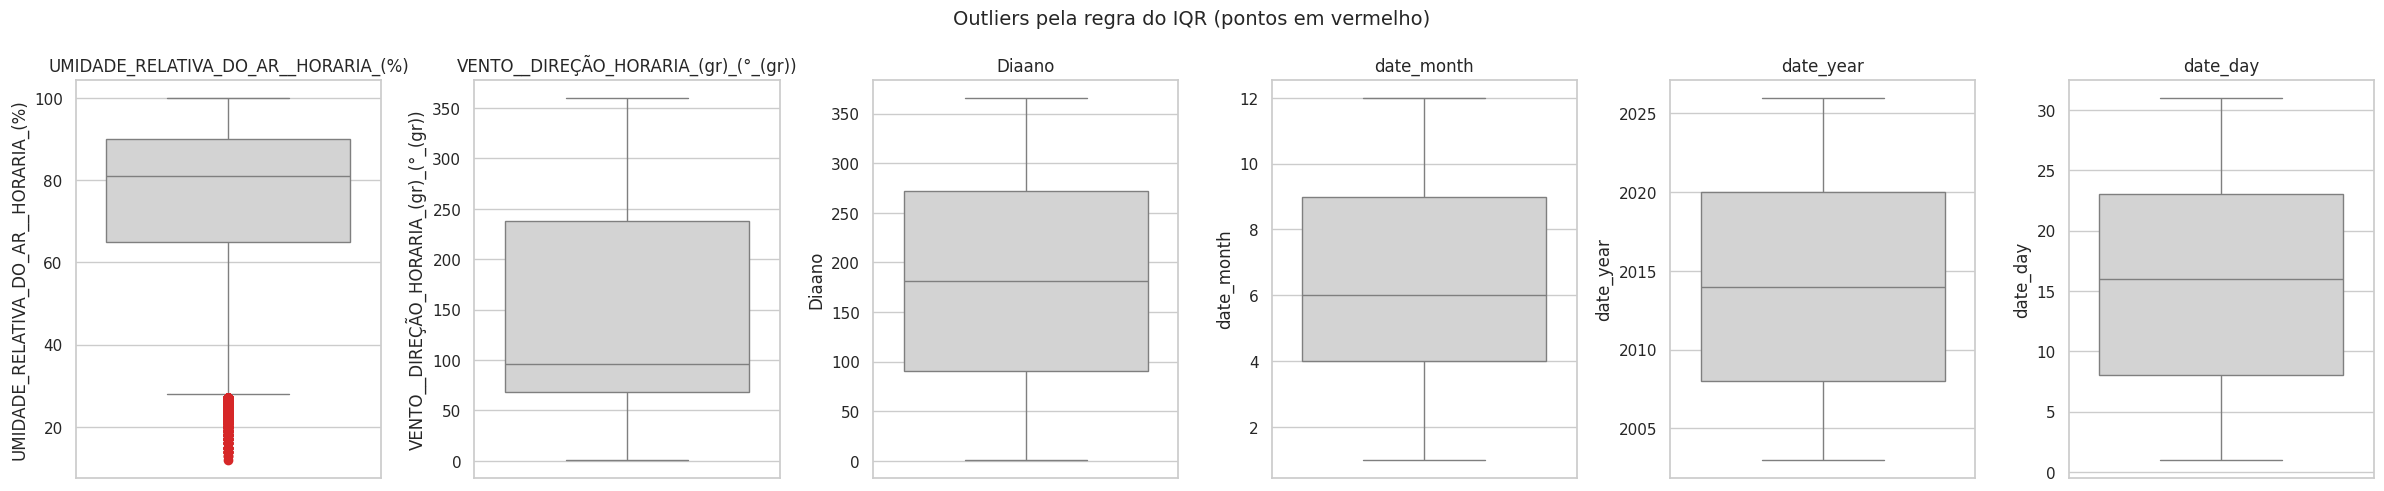

In [20]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df,
        y=col,
        color=COR_NEUTRA,
        flierprops=dict(
            markerfacecolor=COR_ALERTA,
            markeredgecolor=COR_ALERTA,
            marker="o"
        ),
        ax=axes[i]
    )
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Resposta: Pela regra do IQR, foram identificados 1.406 possíveis outliers apenas na variável de umidade relativa do ar, correspondentes a valores abaixo de 27,5%. As demais variáveis analisadas não apresentaram outliers por esse critério. Como valores baixos de umidade ainda podem ser fisicamente possíveis, esses casos não devem ser considerados erros automaticamente. Portanto, serão tratados inicialmente como outliers estatísticos legítimos e mantidos nos dados, a menos que outras evidências indiquem erro de medição.

### Decidindo o Tratamento dos Dados Ausentes

Após a análise dos dados ausentes, a coluna RADIACAO_GLOBAL_(Kj/m²), que apresentava aproximadamente 74,86% de valores faltantes, foi removida por ultrapassar o limite de 50% adotado. A coluna RADIACAO_GLOBAL_(KJ/m²) foi mantida, pois apresenta aproximadamente 40,69% de valores ausentes. Como remover todas as linhas afetadas causaria uma perda muito grande de observações, optamos por preencher os valores ausentes dessa variável utilizando a mediana, uma medida menos sensível a assimetrias e valores extremos.

In [21]:
# Guardar uma cópia ANTES de qualquer tratamento
df_antes = df.copy()

# Remover a coluna com mais de 50% de valores ausentes
col_remover = "RADIACAO_GLOBAL_(Kj/m²)"

if col_remover in df.columns:
    df.drop(columns=[col_remover], inplace=True)

# Tratar a outra coluna de radiação
col_rad = "RADIACAO_GLOBAL_(KJ/m²)"

df[col_rad] = pd.to_numeric(df[col_rad], errors="coerce")

ausentes_antes = df[col_rad].isna().sum()
mediana_rad = df[col_rad].median()

df[col_rad] = df[col_rad].fillna(mediana_rad)

ausentes_depois = df[col_rad].isna().sum()

print(f"Ausentes antes: {ausentes_antes}")
print(f"Mediana utilizada: {mediana_rad:.2f}")
print(f"Ausentes depois: {ausentes_depois}")
print(f"Dimensão final: {df.shape}")

Ausentes antes: 84154
Mediana utilizada: 736.45
Ausentes depois: 0
Dimensão final: (206808, 27)


### Decidindo o Tratamento dos Outliers

Diferente dos dados ausentes, os outliers não serão removidos automaticamente. Pela regra do IQR, foram identificados 1.406 possíveis outliers na umidade relativa do ar, correspondentes a valores abaixo de 27,5%. Esses valores, embora estatisticamente incomuns, ainda são fisicamente possíveis para a variável. Portanto, eles serão considerados outliers estatísticos legítimos e mantidos no dataset. Não será aplicada transformação nesta etapa, pois não há evidência de que esses valores sejam erros de coleta.

In [22]:
col_umidade = "UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"

lim_inf, lim_sup = limites_iqr(df[col_umidade])

n_outliers = (
    (df[col_umidade] < lim_inf) |
    (df[col_umidade] > lim_sup)
).sum()

print(f"Limite inferior: {lim_inf:.2f}")
print(f"Limite superior: {lim_sup:.2f}")
print(f"Outliers identificados: {n_outliers}")
print("Tratamento: os valores serão mantidos.")

Limite inferior: 27.50
Limite superior: 127.50
Outliers identificados: 1406
Tratamento: os valores serão mantidos.


Resposta: Os 1.406 valores identificados pelo IQR na umidade relativa do ar serão mantidos. Apesar de serem estatisticamente extremos, eles permanecem dentro de valores fisicamente possíveis e não há evidência de erro de medição. Dessa forma, foram classificados como outliers estatísticos legítimos, não sendo necessária sua remoção ou transformação neste momento.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os dados ausentes e decidimos manter os outliers identificados. Agora repetimos as estatísticas descritivas para comparar os dados antes e depois do tratamento e verificar o efeito das decisões tomadas.

In [23]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
UMIDADE_RELATIVA_DO_AR__HORARIA_(%),76.22,81.00,17.32,12.00,100.00,-0.88,0.03
VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),140.19,96.00,101.05,1.00,360.00,0.77,-0.85
Diaano,181.94,181.00,104.84,1.00,366.00,0.02,-1.19
date_month,6.48,6.00,3.43,1.00,12.00,0.01,-1.19
date_year,2014.37,2014.00,6.81,2003.00,2026.00,0.00,-1.20
date_day,15.73,16.00,8.80,1.00,31.00,0.01,-1.19


### Comparando "antes"x "depois""



In [24]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})

comparacao["delta_skewness"] = (
    comparacao["skewness_depois"] - comparacao["skewness_antes"]
).round(3)

comparacao["delta_kurtosis"] = (
    comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]
).round(3)

comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
UMIDADE_RELATIVA_DO_AR__HORARIA_(%),-0.881,-0.881,0.032,0.032,0.0,0.0
VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),0.770,0.770,-0.854,-0.854,0.0,0.0
Diaano,0.020,0.020,-1.187,-1.187,0.0,0.0
date_month,0.010,0.010,-1.195,-1.195,0.0,0.0
date_year,0.003,0.003,-1.197,-1.197,0.0,0.0
date_day,0.006,0.006,-1.194,-1.194,0.0,0.0


Resposta: Não foram observadas mudanças na assimetria ou na curtose das variáveis analisadas. Isso era esperado, pois os outliers da umidade relativa do ar foram mantidos e o tratamento dos valores ausentes ocorreu na variável de radiação global, que não faz parte de VARS_QUANT. Portanto, o tratamento realizado não alterou essas distribuições.

**A umidade relativa do ar ainda rejeita normalidade?**

Resposta: Sim. O resultado permaneceu praticamente igual após o tratamento, com estatística de aproximadamente **0,9219** e p-valor muito menor que 0,05. A umidade relativa do ar não foi modificada durante o tratamento, portanto era esperado que seu comportamento permanecesse o mesmo. O teste continua fornecendo evidência contra a normalidade.

In [25]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(
    df["UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"].dropna()
)

print(
    f"Shapiro-Wilk (antes) — Umidade: "
    f"estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}"
)

print(
    f"Shapiro-Wilk (depois) — Umidade: "
    f"estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}"
)

Shapiro-Wilk (antes) — Umidade: estatística=0.9219, p-valor=1.905e-120
Shapiro-Wilk (depois) — Umidade: estatística=0.9219, p-valor=1.905e-120


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 206808.
  res = hypotest_fun_out(*samples, **kwds)


**Visualizando antes x depois, lado a lado**

Vamos comparar a distribuição da radiação global antes e depois da imputação dos valores ausentes pela mediana. Também exibimos a umidade relativa do ar para confirmar que sua distribuição permaneceu inalterada, já que os outliers foram mantidos.

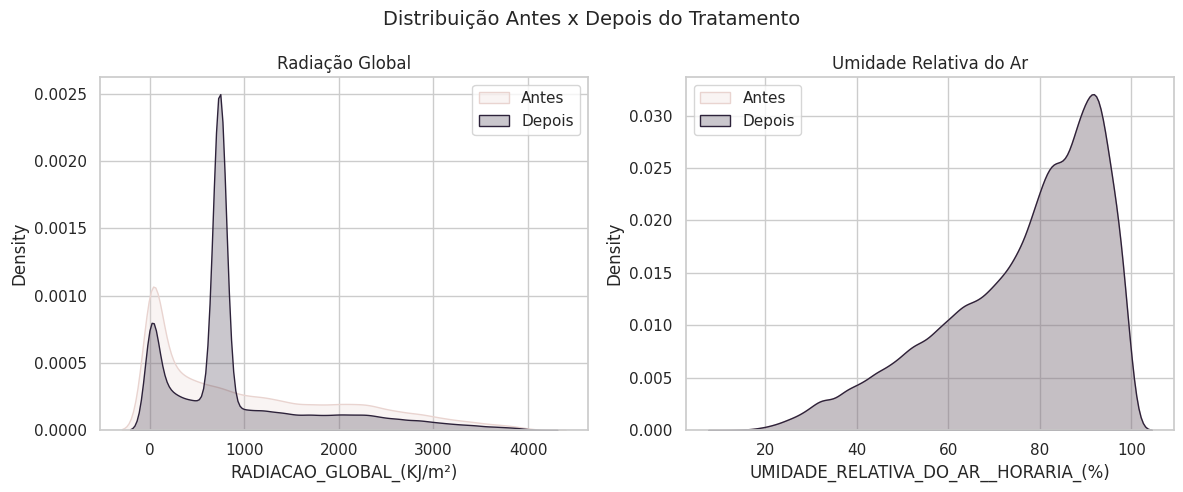

In [26]:
col_rad = "RADIACAO_GLOBAL_(KJ/m²)"
col_umidade = "UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Radiação global
rad_antes = pd.to_numeric(df_antes[col_rad], errors="coerce")

sns.kdeplot(
    rad_antes.dropna(),
    color=COR_CONTEXTO,
    fill=True,
    label="Antes",
    ax=axes[0]
)

sns.kdeplot(
    df[col_rad].dropna(),
    color=COR_DESTAQUE,
    fill=True,
    label="Depois",
    ax=axes[0]
)

axes[0].set_title("Radiação Global")
axes[0].legend()

# Umidade relativa do ar
sns.kdeplot(
    df_antes[col_umidade].dropna(),
    color=COR_CONTEXTO,
    fill=True,
    label="Antes",
    ax=axes[1]
)

sns.kdeplot(
    df[col_umidade].dropna(),
    color=COR_DESTAQUE,
    fill=True,
    label="Depois",
    ax=axes[1]
)

axes[1].set_title("Umidade Relativa do Ar")
axes[1].legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)

plt.tight_layout()
plt.show()

**Pra discutir:** a distribuição da radiação global mudou após o preenchimento dos valores ausentes pela mediana? A distribuição da umidade permaneceu igual, como esperado após a decisão de manter seus outliers?

**Resposta:** A distribuição da radiação global apresentou alteração após o tratamento, pois os valores ausentes foram preenchidos pela mediana de **736,45**. Já a distribuição da umidade relativa do ar permaneceu praticamente inalterada, como esperado, pois seus outliers foram mantidos e nenhum tratamento foi aplicado nessa variável.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




In [27]:
VARS_QUAL = ["Hora_UTC", "municipio"]

#### Frequências absolutas e relativas

In [28]:
df["Hora_UTC"] = df["Hora_UTC"].astype(str).str.strip()

mask = df["Hora_UTC"].str.match(r"^\d{4} UTC$")

df.loc[mask, "Hora_UTC"] = (
    df.loc[mask, "Hora_UTC"]
    .str.replace(" UTC", "", regex=False)
    .str.replace(r"^(\d{2})(\d{2})$", r"\1:\2", regex=True)
)

In [29]:
for col in VARS_QUAL:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)

    print(f"\n--- {col} ---")

    print(
        pd.concat(
            [
                freq_abs.rename("absoluta"),
                freq_rel.rename("relativa")
            ],
            axis=1
        )
    )


--- Hora_UTC ---
          absoluta  relativa
Hora_UTC                    
00:00         8617     0.042
01:00         8617     0.042
02:00         8617     0.042
03:00         8617     0.042
04:00         8617     0.042
05:00         8617     0.042
06:00         8617     0.042
07:00         8617     0.042
08:00         8617     0.042
09:00         8617     0.042
10:00         8617     0.042
11:00         8617     0.042
12:00         8617     0.042
13:00         8617     0.042
14:00         8617     0.042
15:00         8617     0.042
16:00         8617     0.042
17:00         8617     0.042
18:00         8617     0.042
19:00         8617     0.042
20:00         8617     0.042
21:00         8617     0.042
22:00         8617     0.042
23:00         8617     0.042

--- municipio ---
           absoluta  relativa
municipio                    
CURITIBA     206808       1.0


#### Visualizando as frequências

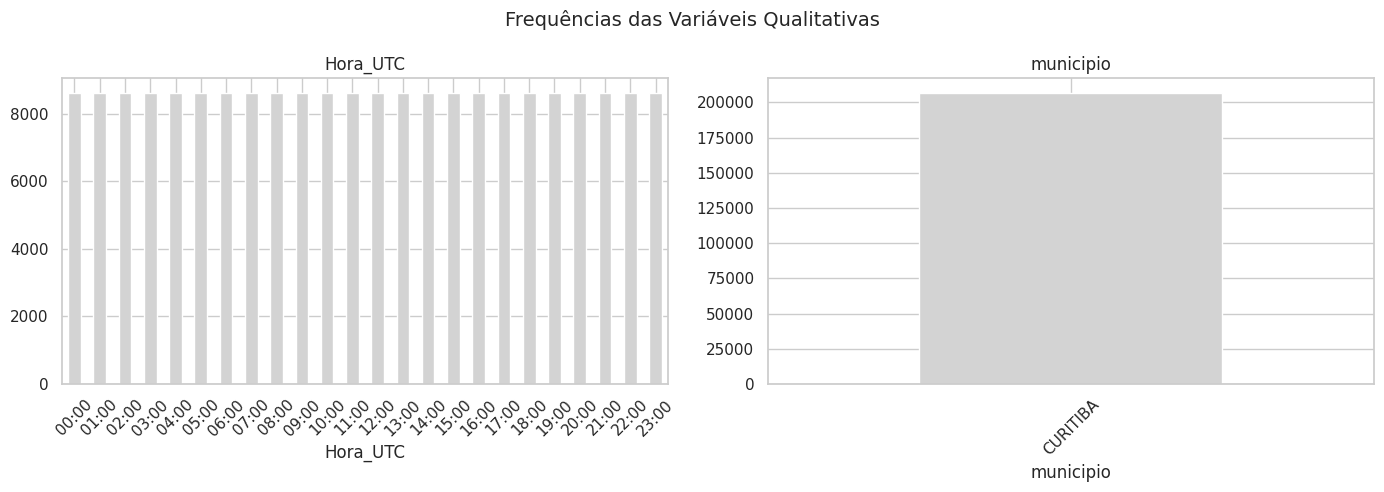

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, col in enumerate(VARS_QUAL):
    df[col].value_counts().sort_index().plot(
        kind="bar",
        color=COR_NEUTRA,
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()



Resposta: A variável Hora_UTC não apresenta desbalanceamento relevante, pois após a padronização dos formatos os registros estão distribuídos de forma uniforme entre as 24 horas do dia. Já a variável municipio possui apenas uma categoria, CURITIBA, correspondente a 100% das observações. Isso é esperado, pois o dataset foi construído especificamente com dados meteorológicos de Curitiba e, portanto, essa variável não é útil para comparar diferentes grupos.

Desbalanceamento entre Categorias

Razão de desbalanceamento — frequência da categoria majoritária dividida pela frequência da categoria minoritária. Quanto maior o valor, maior o desbalanceamento.
Entropia de Shannon normalizada — valores próximos de 1 indicam distribuição mais equilibrada entre as categorias, enquanto valores próximos de 0 indicam forte concentração.

Vamos aplicar essas métricas às variáveis qualitativas do dataset.

In [31]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    n_classes = len(contagens)

    if n_classes > 1:
        razao = contagens.max() / contagens.min()
        props = contagens / contagens.sum()
        ent_normalizada = entropy(props, base=2) / np.log2(n_classes)
    else:
        razao = np.nan
        ent_normalizada = 0.0

    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2) if not np.isnan(razao) else np.nan,
        "entropia_normalizada": round(ent_normalizada, 3)
    })

vars_para_checar = VARS_QUAL

pd.DataFrame({
    col: metrica_desbalanceamento(df[col])
    for col in vars_para_checar
}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Hora_UTC,24.0,1.0,1.0
municipio,1.0,NaN,0.0


Resposta: A variável Hora_UTC apresenta distribuição equilibrada entre suas 24 categorias, com razão de desbalanceamento igual a 1 e entropia normalizada próxima de 1. Já municipio possui apenas uma categoria, CURITIBA, portanto não existe comparação entre categorias e sua entropia normalizada é 0. Isso ocorre porque o dataset contém exclusivamente registros meteorológicos de Curitiba.

### Análise Bivariada

Agora começamos a avaliar como as variáveis do dataset de clima se relacionam entre si.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas principais de correlação:

Pearson: mede principalmente relações lineares e é mais sensível a outliers.
Spearman e Kendall: avaliam relações monotônicas e não exigem normalidade.

Como os testes de normalidade anteriores rejeitaram a hipótese de normalidade para as variáveis analisadas, Spearman será a principal referência, mas calcularemos as três medidas para comparação.

/tmp/ipykernel_12348/4007710715.py:25: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


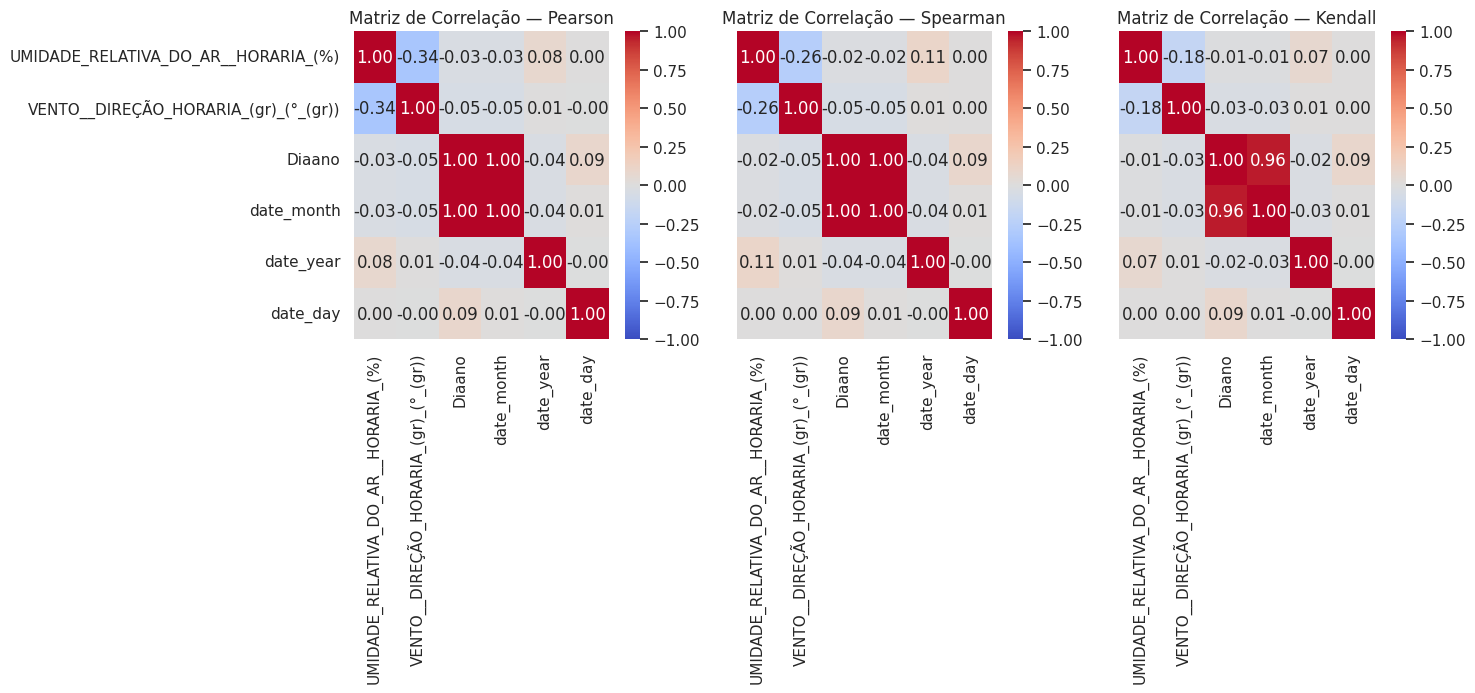

In [32]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

sns.heatmap(
    corr_pearson, annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0]
)
ax[0].set_title("Matriz de Correlação — Pearson")

sns.heatmap(
    corr_spearman, annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1]
)
ax[1].set_title("Matriz de Correlação — Spearman")

sns.heatmap(
    corr_kendall, annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2]
)
ax[2].set_title("Matriz de Correlação — Kendall")

plt.tight_layout()
plt.show()

Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

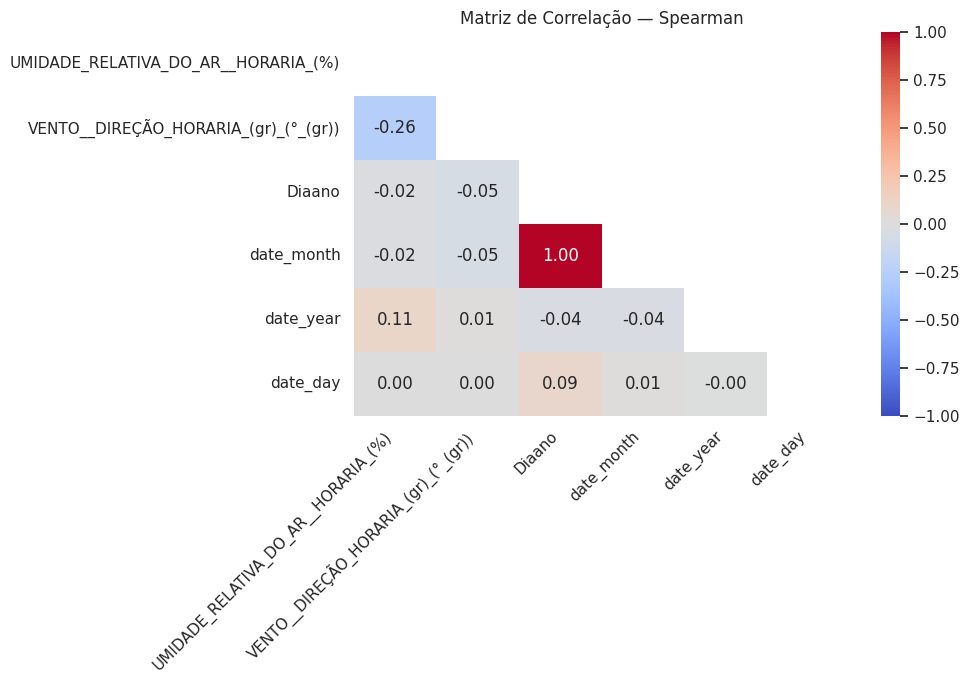

In [33]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.title("Matriz de Correlação — Spearman")
plt.grid(False)
plt.tight_layout()
plt.show()

Resposta: Pearson e Spearman não apresentam divergências muito grandes entre os pares analisados. A maior diferença observada ocorre entre a umidade relativa do ar e a direção do vento, com correlação de -0,35 em Pearson e -0,27 em Spearman, indicando uma relação negativa fraca a moderada. A relação mais forte ocorre entre Diaano e date_month, com correlação próxima de 1, o que é esperado por ambas representarem informações temporais relacionadas ao calendário. Os demais pares apresentam correlações próximas de zero, indicando pouca associação entre essas variáveis.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos a umidade relativa do ar e a direção horária do vento porque, entre as variáveis meteorológicas analisadas, esse foi o par que apresentou a associação mais relevante na matriz de correlação. O gráfico de dispersão permite observar visualmente o comportamento dessa relação.

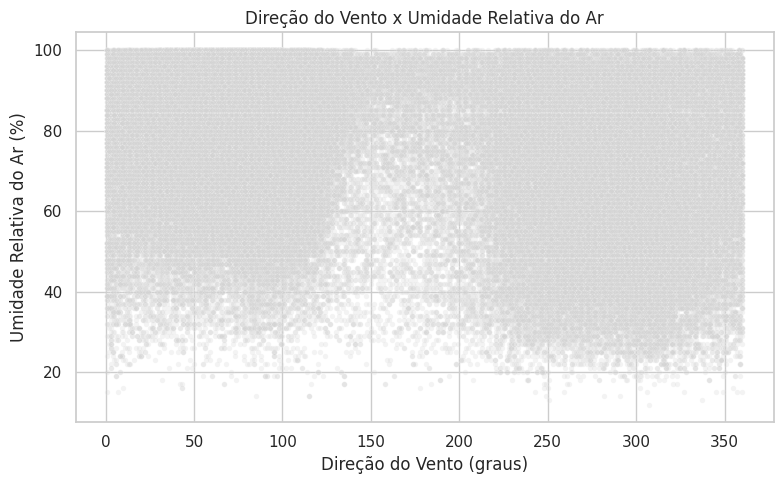

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr))",
    y="UMIDADE_RELATIVA_DO_AR__HORARIA_(%)",
    color=COR_NEUTRA,
    alpha=0.25,
    s=15
)

plt.title("Direção do Vento x Umidade Relativa do Ar")
plt.xlabel("Direção do Vento (graus)")
plt.ylabel("Umidade Relativa do Ar (%)")

plt.tight_layout()
plt.show()

Pra discutir: existe alguma tendência visual entre a direção do vento e a umidade relativa do ar? O gráfico é compatível com a correlação negativa fraca observada anteriormente?

Resposta: O gráfico não mostra uma tendência linear forte entre a direção do vento e a umidade relativa do ar, pois os pontos estão bastante dispersos. Ainda assim, é possível observar uma associação negativa fraca, coerente com a correlação de Spearman de aproximadamente -0,27 encontrada anteriormente. Portanto, a direção do vento apresenta alguma relação com a umidade, mas não é suficiente para explicar sozinha o comportamento dessa variável.

#### Quantitativa x Qualitativa: Comparando Grupos

Para comparar uma variável quantitativa entre categorias, podemos utilizar testes paramétricos ou não-paramétricos. O T-Test e o Mann-Whitney são utilizados quando existem dois grupos, enquanto ANOVA e Kruskal-Wallis são adequados para três ou mais grupos.

Neste dataset não temos uma variável qualitativa binária adequada para a comparação entre dois grupos. A variável Hora_UTC, porém, possui 24 categorias, permitindo comparar as variáveis quantitativas entre os diferentes horários do dia.

Como os testes de normalidade realizados anteriormente rejeitaram a normalidade das variáveis quantitativas, o Kruskal-Wallis será considerado o resultado principal. A ANOVA será calculada apenas para comparação.

In [35]:
resultados_comparacao = []

for col in VARS_QUANT:
    grupos = [
        grupo[col].dropna().values
        for _, grupo in df.groupby("Hora_UTC")
    ]

    grupos = [g for g in grupos if len(g) > 0]

    stat_anova, p_anova = stats.f_oneway(*grupos)
    stat_kw, p_kw = stats.kruskal(*grupos)

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_anova": p_anova,
        "p_valor_kruskal": p_kw,
        "significativo_kruskal": p_kw < 0.05,
        "concordam": (
    np.nan
    if pd.isna(p_anova) or pd.isna(p_kw)
    else (p_anova < 0.05) == (p_kw < 0.05)
)
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_anova,p_valor_kruskal,significativo_kruskal,concordam
variavel,,,,
UMIDADE_RELATIVA_DO_AR__HORARIA_(%),0.0,0.0,True,True
VENTO__DIREÇÃO_HORARIA_(gr)_(°_(gr)),0.0,0.0,True,True
Diaano,1.0,1.0,False,True
date_month,1.0,1.0,False,True
date_year,NaN,1.0,False,NaN
date_day,1.0,1.0,False,True


Pra discutir: alguma variável quantitativa apresenta diferenças significativas entre os diferentes horários do dia? ANOVA e Kruskal-Wallis chegam às mesmas conclusões? Como as variáveis não seguem normalidade, o resultado do Kruskal-Wallis será utilizado como principal referência.

Resposta: O teste de Kruskal-Wallis indicou diferenças estatisticamente significativas entre os horários do dia para a umidade relativa do ar e para a direção do vento. Já Diaano, date_month, date_year e date_day não apresentaram diferenças significativas entre os horários. ANOVA e Kruskal-Wallis chegaram à mesma conclusão nas variáveis em que ambos produziram resultados válidos. Como as variáveis quantitativas não seguem normalidade, o Kruskal-Wallis é utilizado como principal referência.



ANOVA — Umidade entre horários: estatística=7449.059, p-valor=0
Kruskal-Wallis — Umidade entre horários: estatística=93686.792, p-valor=0


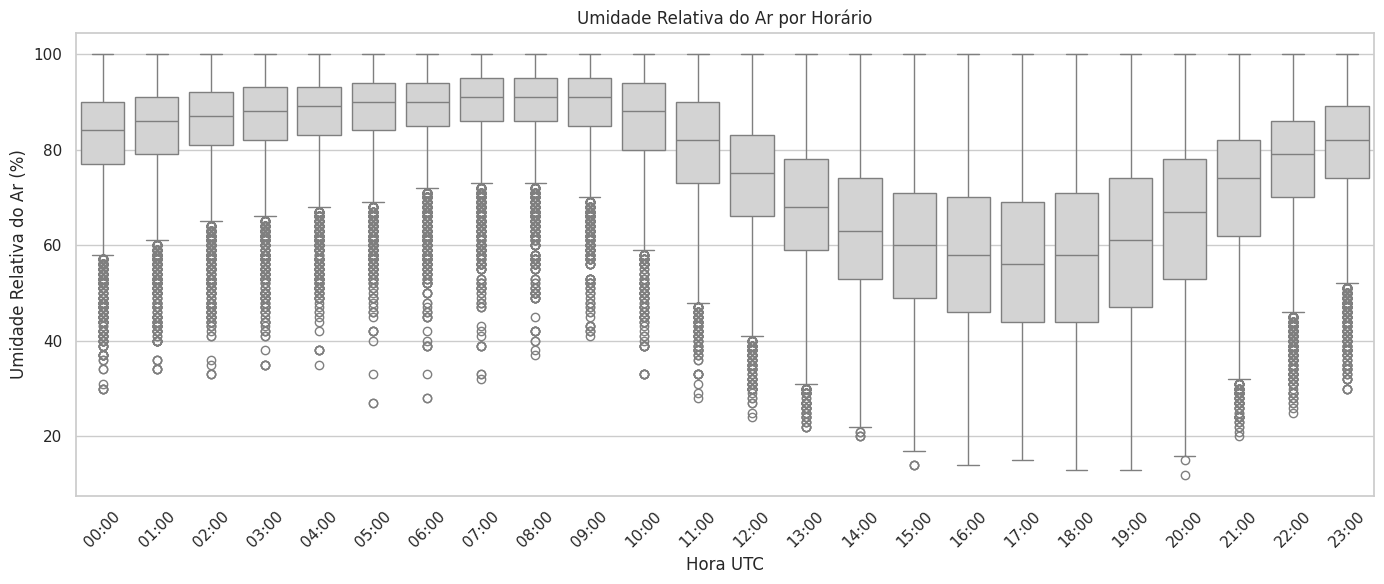

In [36]:
grupos_umidade = [
    grupo["UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"].dropna().values
    for _, grupo in df.groupby("Hora_UTC")
]

stat_anova, p_anova = stats.f_oneway(*grupos_umidade)
stat_kw, p_kw = stats.kruskal(*grupos_umidade)

print(
    f"ANOVA — Umidade entre horários: "
    f"estatística={stat_anova:.3f}, p-valor={p_anova:.5g}"
)

print(
    f"Kruskal-Wallis — Umidade entre horários: "
    f"estatística={stat_kw:.3f}, p-valor={p_kw:.5g}"
)

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="Hora_UTC",
    y="UMIDADE_RELATIVA_DO_AR__HORARIA_(%)",
    color=COR_NEUTRA
)

plt.title("Umidade Relativa do Ar por Horário")
plt.xlabel("Hora UTC")
plt.ylabel("Umidade Relativa do Ar (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Pra discutir: ANOVA e Kruskal-Wallis indicam diferença na umidade relativa do ar entre os diferentes horários do dia? O boxplot mostra visualmente mudanças na distribuição da umidade ao longo das horas?

Resposta: Tanto a ANOVA quanto o teste de Kruskal-Wallis indicam diferenças estatisticamente significativas na umidade relativa do ar entre os diferentes horários do dia. O boxplot confirma visualmente esse comportamento: a umidade tende a ser mais elevada durante a madrugada e o início da manhã, diminui ao longo do dia, atingindo valores mais baixos durante a tarde, e volta a aumentar durante a noite. Como a variável não apresenta distribuição normal, o resultado do Kruskal-Wallis é utilizado como principal referência.

Qualitativa x Qualitativa

O teste Qui-Quadrado de independência é utilizado para verificar se existe associação entre duas variáveis categóricas. Neste dataset, porém, não há duas variáveis qualitativas adequadas para esse teste. Hora_UTC possui 24 categorias, enquanto municipio contém apenas uma categoria (CURITIBA) em todas as observações.

Como municipio não apresenta variação, não é possível realizar uma análise de associação categórica significativa entre essas duas variáveis. Portanto, o teste Qui-Quadrado não será aplicado nesta etapa.

#### Avaliação de Fairness

A análise de fairness busca identificar possíveis diferenças de comportamento de um sistema ou de um desfecho entre grupos sensíveis, como sexo, faixa etária, raça ou outros atributos protegidos.

No dataset de clima de Curitiba não existem atributos sensíveis relacionados a indivíduos, nem uma variável-alvo associada a decisões ou resultados sobre pessoas. As variáveis presentes representam informações meteorológicas, como umidade, vento, radiação e tempo.

Portanto, uma avaliação de fairness entre grupos protegidos não se aplica a este conjunto de dados e não será realizada nesta etapa.

#### Outliers bivariados

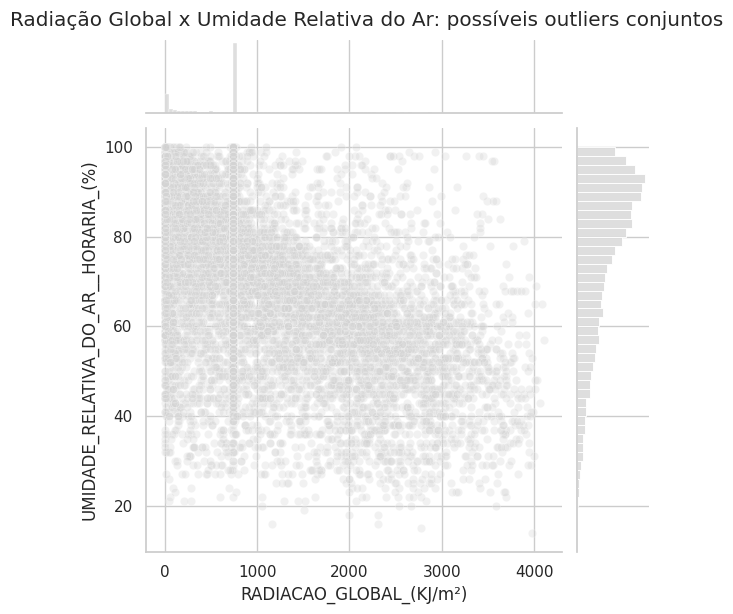

In [37]:
amostra_plot = df[
    ["RADIACAO_GLOBAL_(KJ/m²)", "UMIDADE_RELATIVA_DO_AR__HORARIA_(%)"]
].dropna().sample(n=15000, random_state=42)

sns.jointplot(
    data=amostra_plot,
    x="RADIACAO_GLOBAL_(KJ/m²)",
    y="UMIDADE_RELATIVA_DO_AR__HORARIA_(%)",
    color=COR_NEUTRA,
    alpha=0.3,
    height=6
)

plt.suptitle(
    "Radiação Global x Umidade Relativa do Ar: possíveis outliers conjuntos",
    y=1.02
)

plt.show()

Pra discutir: existe algum ponto ou conjunto de pontos que não parecia tão extremo nas análises univariadas, mas que se destaca pela combinação entre radiação global e umidade relativa do ar?

Resposta: O gráfico mostra algumas combinações menos frequentes entre radiação global e umidade relativa do ar, principalmente em situações de radiação muito alta associada a valores baixos de umidade. Esses pontos podem ser considerados candidatos a outliers bivariados, pois se destacam pela combinação das duas variáveis. No entanto, apenas o gráfico não é suficiente para afirmar que são erros ou outliers reais, sendo necessária uma análise adicional antes de qualquer remoção.

#### Análise Multivariada

##### Matriz de Correlação

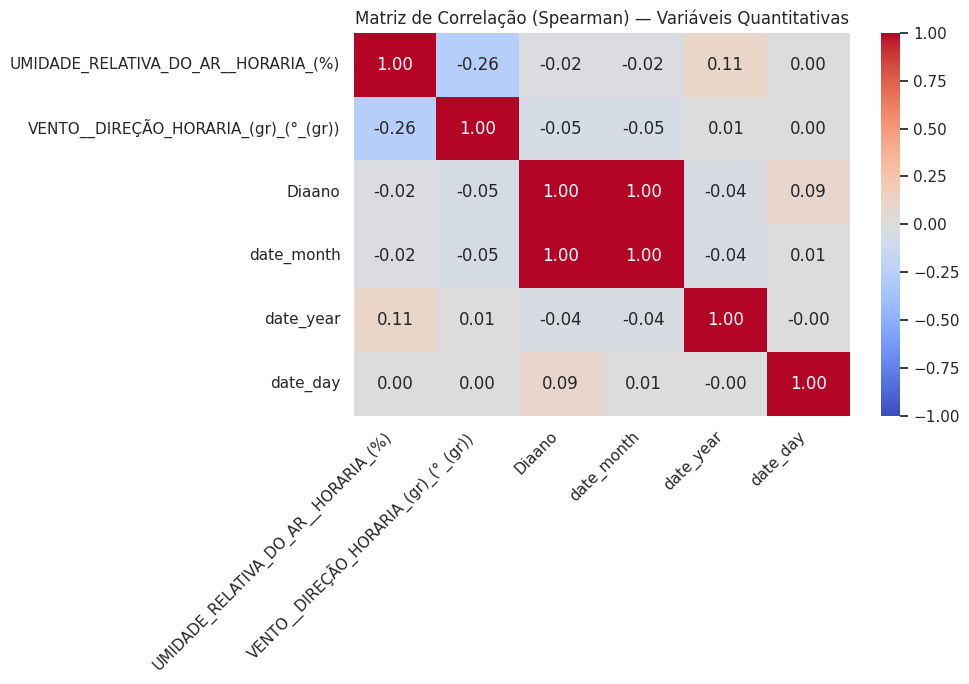

In [38]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[VARS_QUANT].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

Resposta: Sim. A relação entre Diaano e date_month apresenta correlação de Spearman próxima de 1, indicando uma associação muito forte. Isso é esperado porque ambas representam informações temporais derivadas da data e, portanto, podem carregar informação redundante. As demais correlações são fracas, sendo a relação entre umidade relativa do ar e direção do vento de aproximadamente -0,27, abaixo do limite considerado moderado.

##### Correlograma

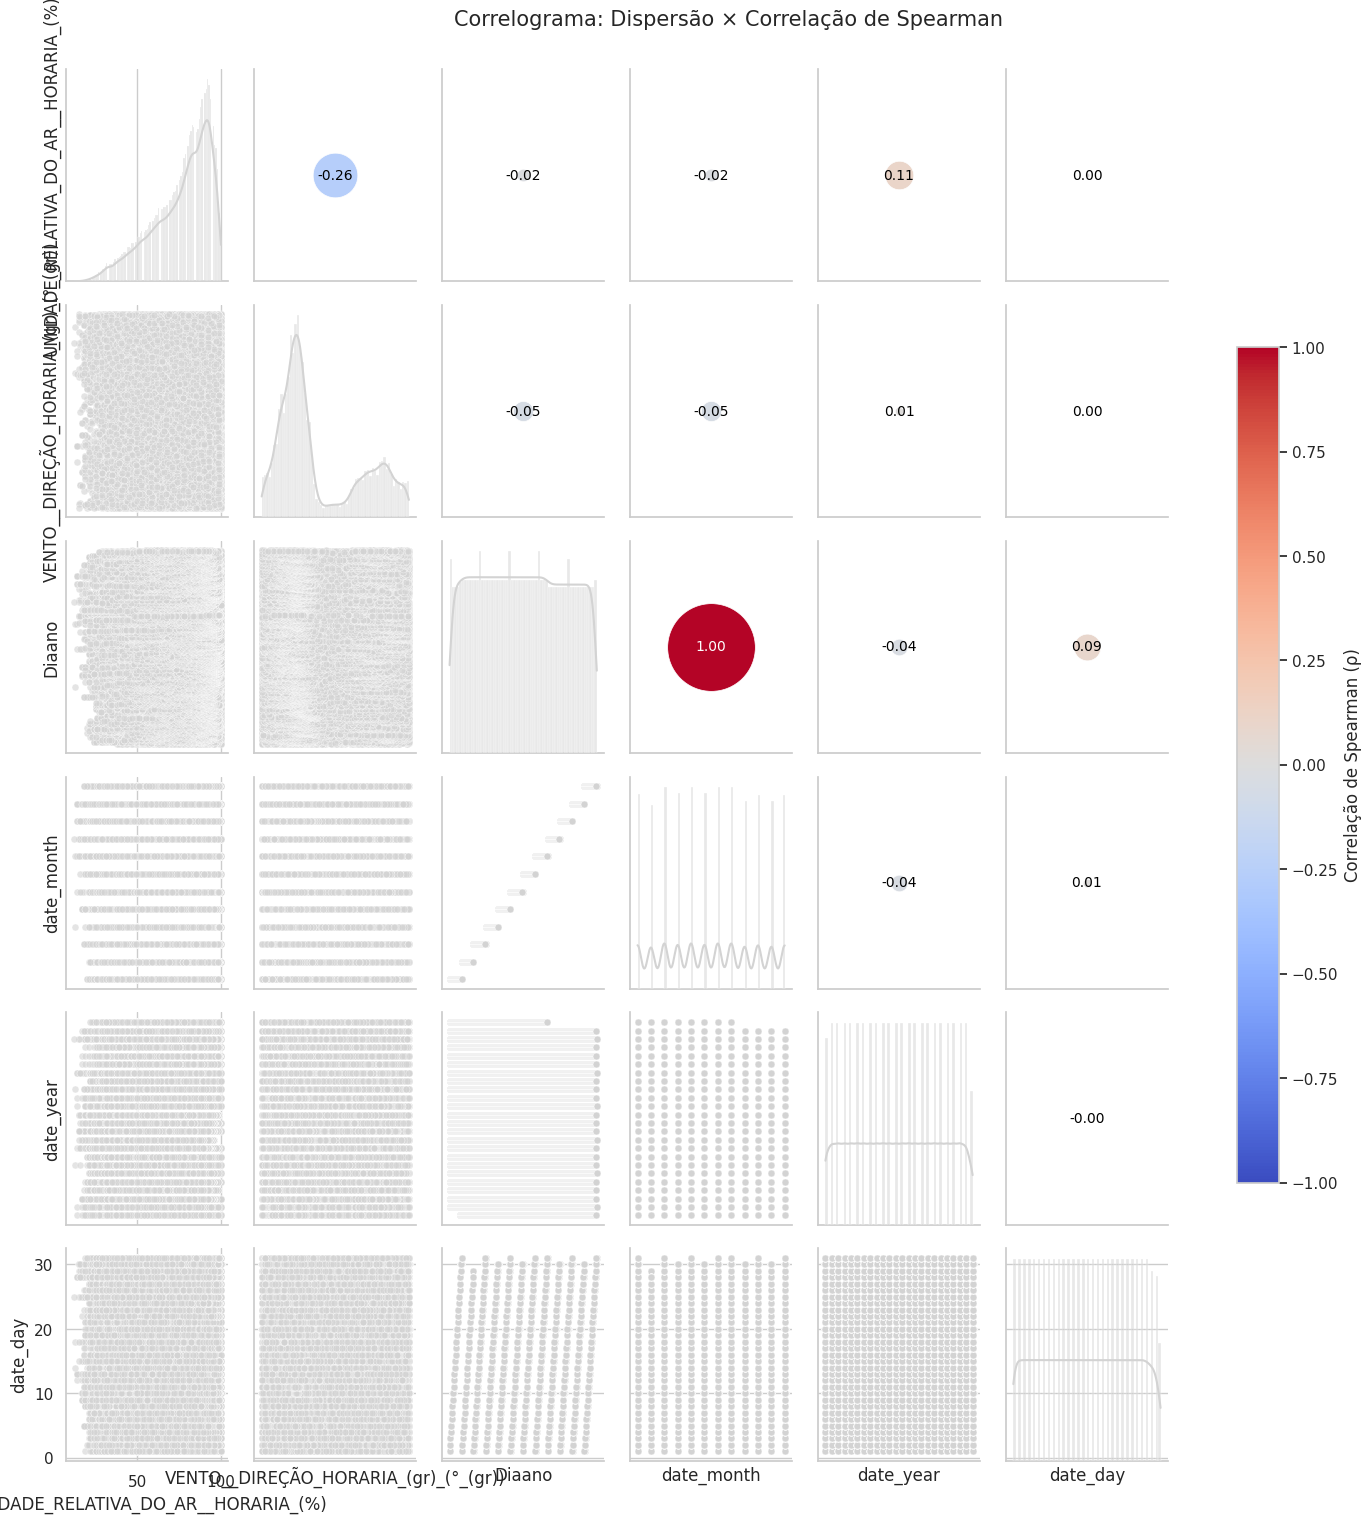

In [39]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r, _ = stats.spearmanr(x, y, nan_policy="omit")

    ax = plt.gca()

    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r],
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        transform=ax.transAxes,
        edgecolor="white",
        linewidth=0.5
    )

    ax.annotate(
        f"{r:.2f}",
        xy=(0.5, 0.5),
        xycoords=ax.transAxes,
        ha="center",
        va="center",
        fontsize=10,
        color="white" if abs(r) > 0.5 else "black"
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)


g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)

g.map_lower(
    sns.scatterplot,
    color=COR_NEUTRA,
    alpha=0.6,
    s=25
)

g.map_diag(
    sns.histplot,
    color=COR_NEUTRA,
    kde=True
)

g.map_upper(circulo_correlacao)

sm = ScalarMappable(
    norm=Normalize(-1, 1),
    cmap="coolwarm"
)

sm.set_array([])

g.fig.colorbar(
    sm,
    ax=g.axes,
    shrink=0.6,
    label="Correlação de Spearman (ρ)"
)

g.fig.suptitle(
    "Correlograma: Dispersão × Correlação de Spearman",
    y=1.02,
    fontsize=15
)

plt.show()

## Principais conclusões

1. O dataset contém 206.808 observações e não apresentou registros duplicados. Foram encontrados valores ausentes em duas colunas relacionadas à radiação global.

2. A coluna `RADIACAO_GLOBAL_(Kj/m²)` apresentou aproximadamente 74,86% de valores ausentes e foi removida pelo critério adotado de 50%. A coluna `RADIACAO_GLOBAL_(KJ/m²)`, com aproximadamente 40,69% de ausências, foi mantida e seus valores faltantes foram preenchidos pela mediana de 736,45.

3. Pela regra do IQR, foram identificados 1.406 possíveis outliers na umidade relativa do ar, todos abaixo de 27,5%. Como esses valores ainda são fisicamente possíveis e não há evidência de erro de medição, eles foram mantidos.

4. A umidade relativa do ar apresentou evidências contra uma distribuição normal e mostrou variação relevante ao longo do dia, com valores geralmente maiores durante a madrugada e início da manhã e menores durante a tarde.

5. As correlações entre as variáveis analisadas foram, em geral, fracas. Entre as variáveis meteorológicas analisadas, destacou-se uma associação negativa fraca entre a direção do vento e a umidade relativa do ar.

## Declaração de Uso de IA

Foi utilizado o ChatGPT, da OpenAI, como ferramenta de apoio pontual durante o desenvolvimento da atividade. O uso foi principalmente para esclarecer dúvidas sobre alguns trechos de código, ajudar na correção de erros durante a execução no Google Colab e revisar a redação de algumas interpretações dos resultados.

A adaptação do notebook ao dataset de clima de Curitiba, a execução das análises, a verificação dos resultados e as decisões sobre quais etapas faziam ou não sentido para o conjunto de dados foram realizadas por mim. As sugestões fornecidas pela IA foram avaliadas e ajustadas conforme os resultados obtidos no próprio notebook.